In [18]:
file_name = "NPC1_2025_09_01_15_32_39"
file_path = rf"C:\Maze\Video Data"

output_video_path = rf"{file_path}\{file_name}_stitched.avi"
video1_path = rf"{file_path}\{file_name}_cam2.avi"
video2_path = rf"{file_path}\{file_name}_cam1.avi"
stitched_image_path = rf"{file_path}\{file_name}_stitched_image.jpg"

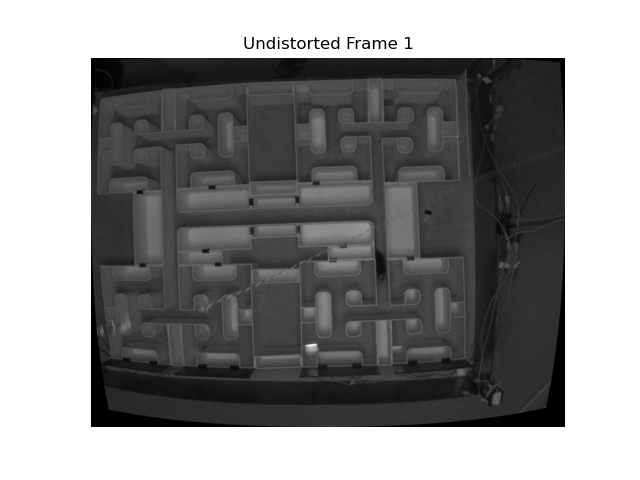

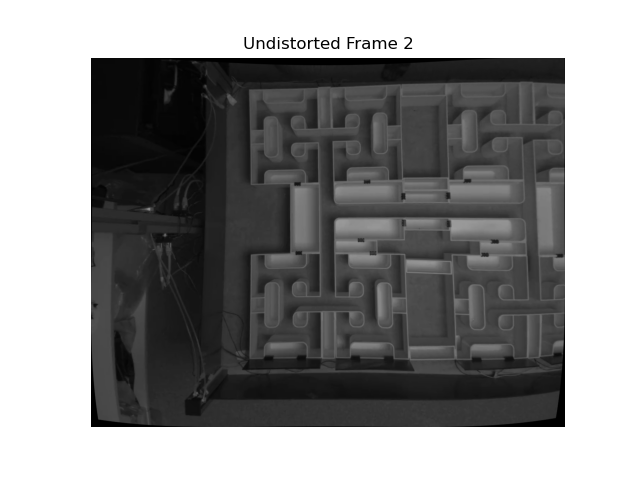

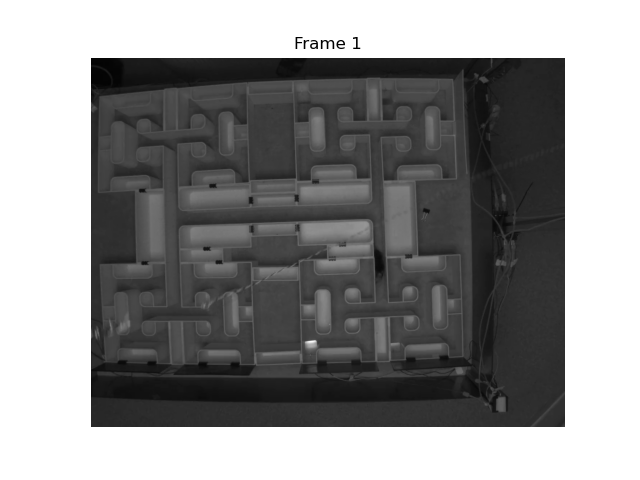

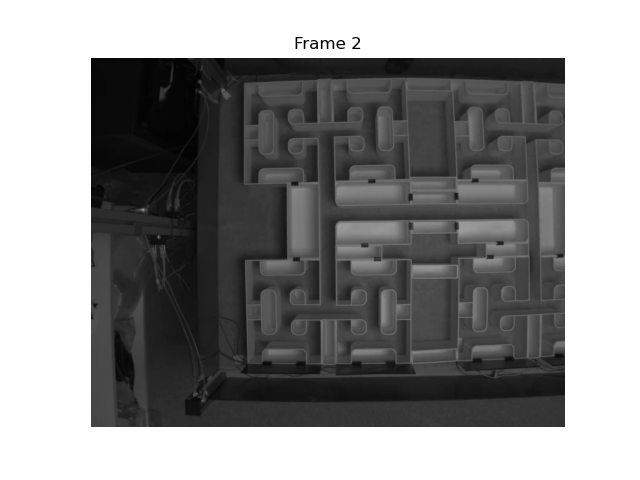

In [19]:
import cv2
import numpy as np

import matplotlib.pyplot as plt

def undistort_image(image, camera_matrix, dist_coeffs):
    """
    Undistort the given image using the camera matrix and distortion coefficients.
    """
    h, w = image.shape[:2]
    new_camera_matrix, roi = cv2.getOptimalNewCameraMatrix(camera_matrix, dist_coeffs, (w, h), 1, (w, h))
    undistorted_image = cv2.undistort(image, camera_matrix, dist_coeffs, None, new_camera_matrix)
    return undistorted_image

def display_with_grid(image, title):
    """
    Display the image with a grid overlay.
    """
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.xticks(np.arange(0, image.shape[1], 50))
    plt.yticks(np.arange(0, image.shape[0], 50))
    plt.grid(color='white', linestyle='--', linewidth=0.2)
    plt.show()

# # Load the first frame from two videos
# file_name = "17L_2025_05_27_15_20_41"
# video1_path = rf"F:\My Drive\no headstage vids\17L\{file_name}_cam2.avi"
# video2_path = rf"F:\My Drive\no headstage vids\17L\{file_name}_cam1.avi"

cap1 = cv2.VideoCapture(video1_path)
cap2 = cv2.VideoCapture(video2_path)

N = 100  # Set your desired frame index here

cap1.set(cv2.CAP_PROP_POS_FRAMES, N)
cap2.set(cv2.CAP_PROP_POS_FRAMES, N)

ret1, frame1 = cap1.read()
ret2, frame2 = cap2.read()

cap1.release()
cap2.release()

if not ret1 or not ret2:
    raise ValueError("Failed to read frames from one or both videos.")

# Example camera matrix and distortion coefficients (replace with actual calibration data)
camera_matrix1 = np.array([[800, 0, 640],
                          [0, 800, 360],
                          [0, 0, 1]], dtype=np.float32)
dist_coeffs1 = np.array([-0.1, 0.15, 0, 0], dtype=np.float32)

camera_matrix2 = np.array([[800, 0, 640],
                          [0, 800, 360],
                          [0, 0, 1]], dtype=np.float32)
dist_coeffs2 = np.array([-0.2, 0.1, 0, 0], dtype=np.float32)

# Undistort the images
undistorted_frame1 = undistort_image(frame1, camera_matrix1, dist_coeffs1)
undistorted_frame2 = undistort_image(frame2, camera_matrix2, dist_coeffs2)

# Display the images with grid overlay
display_with_grid(undistorted_frame1, "Undistorted Frame 1")
display_with_grid(undistorted_frame2, "Undistorted Frame 2")
display_with_grid(frame1, "Frame 1")
display_with_grid(frame2, "Frame 2")

In [20]:
video1_path

'C:\\Maze\\Video Data\\NPC1_2025_09_01_15_32_39_cam2.avi'

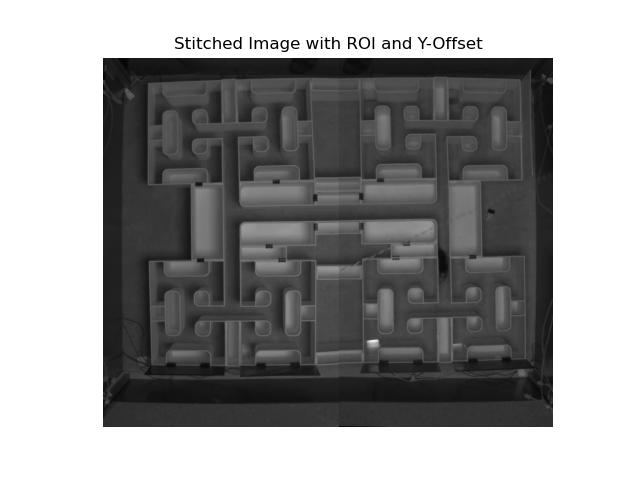

In [21]:
def stitch_images_with_roi_and_y_offset(img1, img2, roi1, roi2, y_offset1=0, y_offset2=0, resize_factor1=1.0, resize_factor2=1.0, rotation_angle1=0, rotation_angle2=0):
    """
    Stitch two images together with adjustable ROIs, resizing, rotation, and y-offset alignment.

    Parameters:
    - img1: First image.
    - img2: Second image.
    - roi1: Tuple (start_x, end_x) for img1.
    - roi2: Tuple (start_x, end_x) for img2.
    - y_offset1: Vertical offset for img1.
    - y_offset2: Vertical offset for img2.
    - resize_factor1: Scaling factor for img1.
    - resize_factor2: Scaling factor for img2.
    - rotation_angle1: Rotation angle for img1 in degrees.
    - rotation_angle2: Rotation angle for img2 in degrees.

    Returns:
    - stitched_image: The stitched image.
    """
    # Resize images
    img1_resized = cv2.resize(img1, None, fx=resize_factor1, fy=resize_factor1, interpolation=cv2.INTER_LINEAR)
    img2_resized = cv2.resize(img2, None, fx=resize_factor2, fy=resize_factor2, interpolation=cv2.INTER_LINEAR)

    # Rotate images
    def rotate_image(image, angle):
        h, w = image.shape[:2]
        center = (w // 2, h // 2)
        rotation_matrix = cv2.getRotationMatrix2D(center, angle, 1.0)
        return cv2.warpAffine(image, rotation_matrix, (w, h))

    img1_rotated = rotate_image(img1_resized, rotation_angle1)
    img2_rotated = rotate_image(img2_resized, rotation_angle2)

    # Apply y-offsets
    def apply_y_offset(image, y_offset):
        if y_offset > 0:
            return image[y_offset:, :]
        elif y_offset < 0:
            return np.pad(image, ((-y_offset, 0), (0, 0), (0, 0)), mode='constant', constant_values=0)
        return image

    img1_aligned = apply_y_offset(img1_rotated, y_offset1)
    img2_aligned = apply_y_offset(img2_rotated, y_offset2)

    # Ensure both images have the same height
    height = min(img1_aligned.shape[0], img2_aligned.shape[0])
    img1_cropped = img1_aligned[:height, :]
    img2_cropped = img2_aligned[:height, :]

    # Apply ROIs
    img1_roi = img1_cropped[:, roi1[0]:roi1[1]]
    img2_roi = img2_cropped[:, roi2[0]:roi2[1]]

    # Adjust canvas size and stitch the images
    total_width = img1_roi.shape[1] + img2_roi.shape[1]
    canvas = np.zeros((height, total_width, 3), dtype=np.uint8)
    canvas[:, :img2_roi.shape[1]] = img2_roi
    canvas[:, img2_roi.shape[1]:] = img1_roi

    return canvas

# Example usage
roi1 = (510, 1100)  # Start and end x-coordinates for img1 (right)
roi2 = (300, 950)  # Start and end x-coordinates for img2 (left)
stitched_image = stitch_images_with_roi_and_y_offset(frame1, frame2, roi1, roi2, y_offset1=5, y_offset2=0, resize_factor1=1.0, resize_factor2=1.0, rotation_angle1=-1, rotation_angle2=0)

bw_stitched_image = cv2.cvtColor(stitched_image, cv2.COLOR_BGR2GRAY)
hist_eq_stitched_image = cv2.equalizeHist(bw_stitched_image)
# Display the stitched image
# plt.imshow(cv2.cvtColor(stitched_image, cv2.COLOR_BGR2RGB))
plt.imshow(bw_stitched_image, cmap='gray')
# plt.imshow(hist_eq_stitched_image, cmap='gray')
plt.title("Stitched Image with ROI and Y-Offset")
plt.axis('off')
plt.show()

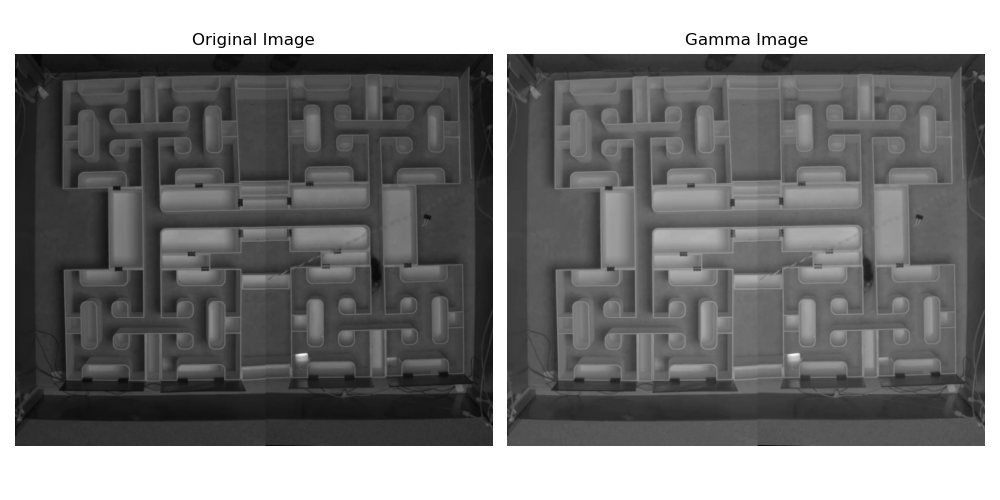

In [29]:
# Convert img1 (which is frame1) to grayscale
gamma = 1.5  # You can adjust this value as needed
inv_gamma = 1.0 / gamma
table = np.array([((i / 255.0) ** inv_gamma) * 255 for i in np.arange(256)]).astype("uint8")
stitched_image_gamma = cv2.LUT(stitched_image, table)

# Plot the original and grayscale images side by side
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(stitched_image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(stitched_image_gamma)
plt.title("Gamma Image")
plt.axis('off')

plt.tight_layout()
plt.show()

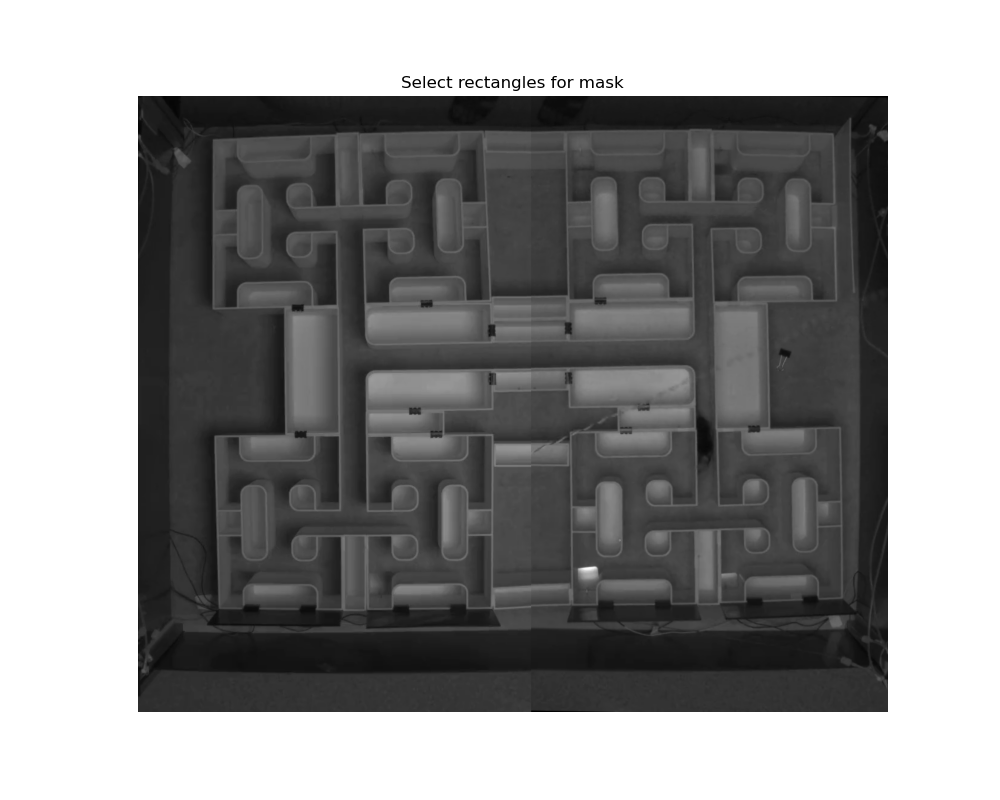

In [31]:
# Interactive rectangle-to-mask tool
# Requirements: ipympl for in-notebook interactivity. Install once: pip install ipympl
from IPython import get_ipython
import importlib, sys, os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.widgets import RectangleSelector
from ipywidgets import HBox, VBox, Button, IntText, HTML, Checkbox, Output
import cv2

# Try to enable ipympl widget backend for interactivity
_has_ipympl = importlib.util.find_spec("ipympl") is not None
if _has_ipympl:
    try:
        get_ipython().run_line_magic('matplotlib', 'widget')
    except Exception:
        pass
else:
    print("Note: ipympl not installed. Install with: pip install ipympl for full interactivity.")
    # Fallback to inline still allows drawing but without live widget chrome
    try:
        get_ipython().run_line_magic('matplotlib', 'inline')
    except Exception:
        pass

# Preconditions
if 'stitched_image' not in globals():
    raise RuntimeError("stitched_image not found. Run the cell that creates it first.")

_img_bgr = stitched_image
_img_rgb = cv2.cvtColor(_img_bgr, cv2.COLOR_BGR2RGB)
H, W = _img_rgb.shape[:2]

# State
_rects = []  # list of dicts with x_min, x_max, y_min, y_max
_patches = []
_out = Output()

# Widgets
btn_undo = Button(description='Undo last', button_style='warning', tooltip='Remove last rectangle')
btn_clear = Button(description='Clear all', button_style='danger', tooltip='Remove all rectangles')
btn_finish = Button(description='Finish', button_style='', tooltip='Finish selection and keep mask in memory')
btn_save = Button(description='Save mask', button_style='success', tooltip='Save binary mask PNG to disk')
pad_px = IntText(value=0, description='Pad(px):', layout={'width':'150px'})
alpha_chk = Checkbox(value=True, description='Show overlays')
info = HTML(value="<b>Instructions:</b> Click-drag to draw rectangles. Press 'q' to close the figure if stuck.")

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(_img_rgb)
ax.set_title("Select rectangles for mask")
ax.axis('off')


def _clamp(v, lo, hi):
    return max(lo, min(hi, v))


def _redraw_overlays():
    # toggle visibility of overlays
    for p in _patches:
        p.set_visible(alpha_chk.value)
    try:
        fig.canvas.draw_idle()
    except Exception:
        fig.canvas.draw()


def _onselect(eclick, erelease):
    if eclick.xdata is None or erelease.xdata is None:
        return
    x0, x1 = int(round(eclick.xdata)), int(round(erelease.xdata))
    y0, y1 = int(round(eclick.ydata)), int(round(erelease.ydata))
    x_min, x_max = sorted([_clamp(x0, 0, W-1), _clamp(x1, 0, W-1)])
    y_min, y_max = sorted([_clamp(y0, 0, H-1), _clamp(y1, 0, H-1)])
    if x_max <= x_min or y_max <= y_min:
        with _out: print("Ignored zero-size rectangle")
        return
    rect = {'x_min': x_min, 'x_max': x_max, 'y_min': y_min, 'y_max': y_max}
    _rects.append(rect)
    patch = plt.Rectangle((x_min, y_min), x_max - x_min, y_max - y_min,
                          fill=False, edgecolor='red', linewidth=2)
    _patches.append(patch)
    ax.add_patch(patch)
    with _out: print(f"Added: {rect}")
    _redraw_overlays()


selector = RectangleSelector(
    ax, _onselect,
    useblit=True,
    button=[1],
    minspanx=5, minspany=5,
    spancoords='pixels',
    interactive=True
)


def _undo_clicked(_):
    if _rects:
        _rects.pop()
        p = _patches.pop()
        p.remove()
        _redraw_overlays()
        with _out: print("Undid last rectangle")


def _clear_clicked(_):
    _rects.clear()
    for p in _patches:
        p.remove()
    _patches.clear()
    _redraw_overlays()
    with _out: print("Cleared all rectangles")


def _finish_clicked(_):
    plt.close(fig)
    with _out:
        print(f"Finished. {len(_rects)} rectangles captured.")
        if _rects:
            print("Example:", _rects[0])


def _save_clicked(_):
    mask = np.zeros((H, W), dtype=np.uint8)
    p = max(0, int(pad_px.value))
    for r in _rects:
        y0 = _clamp(r['y_min']-p, 0, H-1)
        y1 = _clamp(r['y_max']+p, 0, H-1)
        x0 = _clamp(r['x_min']-p, 0, W-1)
        x1 = _clamp(r['x_max']+p, 0, W-1)
        mask[y0:y1+1, x0:x1+1] = 255
    # choose save path
    base_dir = globals().get('file_path', os.getcwd())
    base_name = globals().get('file_name', 'mask')
    out_path = os.path.join(base_dir, f"{base_name}_mask.png")
    ok = cv2.imwrite(out_path, mask)
    with _out:
        print(f"Mask shape: {mask.shape}, nonzero: {int(mask.sum()>0)}; saved={ok} -> {out_path}")


btn_undo.on_click(_undo_clicked)
btn_clear.on_click(_clear_clicked)
btn_finish.on_click(_finish_clicked)
btn_save.on_click(_save_clicked)
alpha_chk.observe(lambda change: _redraw_overlays(), names='value')

ui = VBox([
    info,
    HBox([btn_undo, btn_clear, btn_finish, btn_save, pad_px, alpha_chk]),
    _out
])
ui

In [32]:
rect_coords

[]

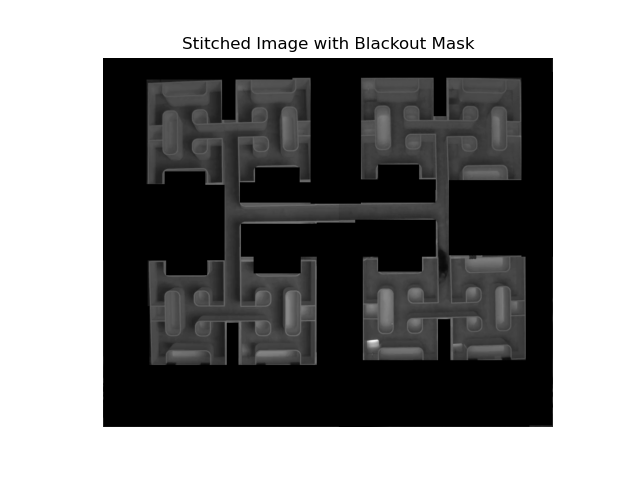

In [35]:
# Create a mask for the stitched_image with all rectangles and 10-pixel frame padding
mask = np.zeros(stitched_image.shape[:2], dtype=np.uint8)
rect_coords = _rects

# Add rectangles from rect_coords
for rect in rect_coords:
    mask[rect['y_min']:rect['y_max']+1, rect['x_min']:rect['x_max']+1] = 1

# Add 10-pixel padding from each edge
# mask[:10, :] = 1
# mask[-10:, :] = 1
# mask[:, :10] = 1
# mask[:, -10:] = 1

# Blackout the frame using the mask
blackout_frame = stitched_image.copy()
blackout_frame[mask == 1] = 0

plt.figure()
plt.imshow(cv2.cvtColor(blackout_frame, cv2.COLOR_BGR2RGB))
plt.title("Stitched Image with Blackout Mask")
plt.axis('off')
plt.show()

In [36]:
# export the stitched_image to a file
cv2.imwrite(rf"{file_path}\{file_name}.png", stitched_image_gamma)

True

In [37]:
#export the blackouted image to a file
cv2.imwrite(rf"{file_path}\{file_name}_blackout.png", blackout_frame)

True

In [ ]:
import cv2
import os
import numpy as np

# Define intermediate and final output paths
temp_output_path = rf"C:\temp\{file_name}_stitched_temp_gamma.avi"
final_output_path = rf"{file_path}\{file_name}_stitched_gamma.mp4"

# Reopen the video files
cap1 = cv2.VideoCapture(video1_path, cv2.CAP_FFMPEG)
cap2 = cv2.VideoCapture(video2_path, cv2.CAP_FFMPEG)

fps1 = cap1.get(cv2.CAP_PROP_FPS)
fps2 = cap2.get(cv2.CAP_PROP_FPS)

# Use average or select one if slightly off
fps = int(round((fps1 + fps2) / 2)) if abs(fps1 - fps2) < 1 else 40

ret1, frame1 = cap1.read()
ret2, frame2 = cap2.read()

if not ret1 or not ret2:
    raise ValueError("Error reading the first frames from the videos.")

# Check for size mismatch
if frame1.shape[:2] != frame2.shape[:2]:
    print("Warning: Input videos have different resolutions. Resizing second frame to match the first.")
    frame2 = cv2.resize(frame2, (frame1.shape[1], frame1.shape[0]))

# First stitched frame for dimensions
stitched_image = stitch_images_with_roi_and_y_offset(
    frame1, frame2, roi1, roi2,
    y_offset1=5, y_offset2=0,
    resize_factor1=1.0, resize_factor2=1.0,
    rotation_angle1=-1, rotation_angle2=0
)

frame_height, frame_width = stitched_image.shape[:2]

# Use FFV1 lossless codec for temporary output
fourcc = cv2.VideoWriter_fourcc(*'FFV1')
out = cv2.VideoWriter(temp_output_path, fourcc, fps, (frame_width, frame_height))

# Write first stitched frame
# stitched_image = cv2.cvtColor(stitched_image, cv2.COLOR_BGR2GRAY)
out.write(stitched_image)

# Continue processing the rest of the video
while True:
    ret1, frame1 = cap1.read()
    ret2, frame2 = cap2.read()

    if not ret1 or not ret2:
        break

    if frame1.shape[:2] != frame2.shape[:2]:
        frame2 = cv2.resize(frame2, (frame1.shape[1], frame1.shape[0]))

    stitched_frame = stitch_images_with_roi_and_y_offset(
        frame1, frame2, roi1, roi2,
        y_offset1=5, y_offset2=0,
        resize_factor1=1.0, resize_factor2=1.0,
        rotation_angle1=-1, rotation_angle2=0
    )

    gamma = 1.5  # You can adjust this value as needed
    inv_gamma = 1.0 / gamma
    table = np.array([((i / 255.0) ** inv_gamma) * 255 for i in np.arange(256)]).astype("uint8")
    stitched_frame = cv2.LUT(stitched_frame, table)
    # blackout the stitched frame
    stitched_frame[mask == 1] = 0

    out.write(stitched_frame)

cap1.release()
cap2.release()
out.release()

print(f"Temporary lossless video saved to {temp_output_path}")

In [3]:
temp_output_path = rf"C:\temp\{file_name}_stitched_temp_gamma.avi"
final_output_path = rf"{file_path}\{file_name}_stitched_blacked.mp4"

In [4]:
import subprocess

ffmpeg_cmd = [
    'ffmpeg',
    '-i', temp_output_path,
    '-c:v', 'libx264',
    '-crf', '18',
    '-preset', 'slow',
    final_output_path
]
subprocess.run(ffmpeg_cmd, check=True)
# # Clean up temporary file
# if os.path.exists(temp_output_path):
#     os.remove(temp_output_path)

print(f"Final stitched video saved to {final_output_path}")

Final stitched video saved to C:\Maze\Video Data\NPC1_2025_08_14_13_02_08_stitched_blacked.mp4


In [21]:
# Clean up temporary file
if os.path.exists(temp_output_path):
    os.remove(temp_output_path)

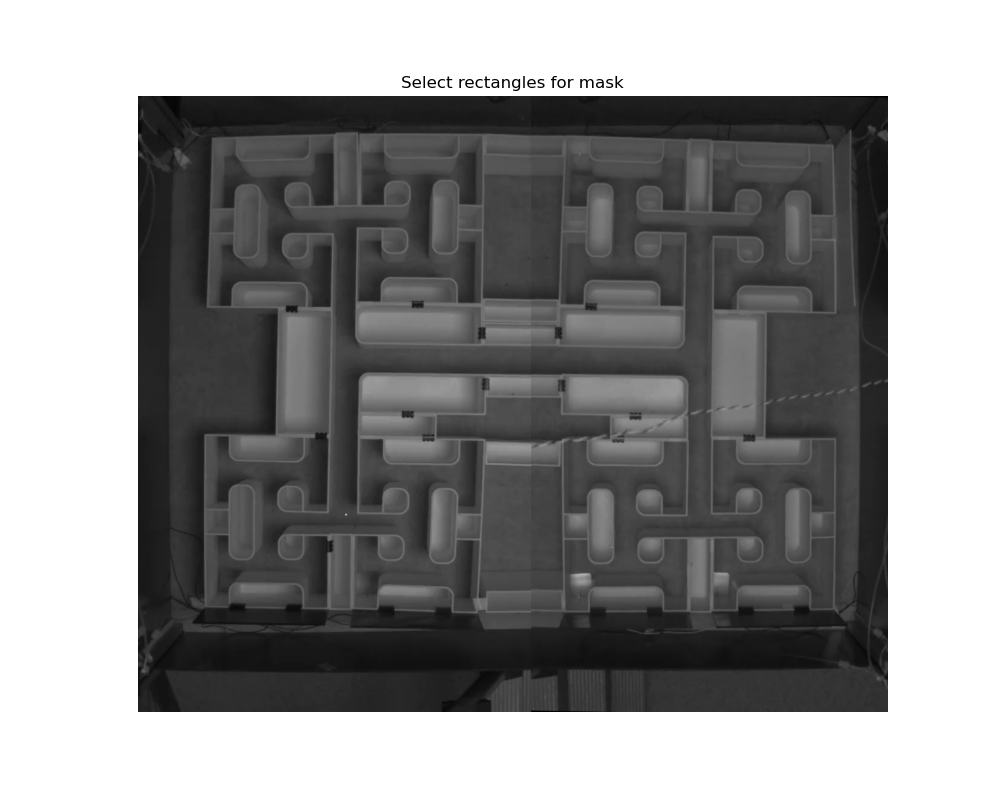

In [16]:
_rects

[{'x_min': 0, 'x_max': 119, 'y_min': 16, 'y_max': 115},
 {'x_min': 136, 'x_max': 1239, 'y_min': 1, 'y_max': 49},
 {'x_min': 1156, 'x_max': 1236, 'y_min': 52, 'y_max': 375},
 {'x_min': 0, 'x_max': 147, 'y_min': 3, 'y_max': 31},
 {'x_min': 5, 'x_max': 112, 'y_min': 82, 'y_max': 552},
 {'x_min': 0, 'x_max': 99, 'y_min': 537, 'y_max': 1015},
 {'x_min': 63, 'x_max': 465, 'y_min': 845, 'y_max': 1018},
 {'x_min': 450, 'x_max': 1239, 'y_min': 853, 'y_max': 1017},
 {'x_min': 1156, 'x_max': 1237, 'y_min': 378, 'y_max': 860},
 {'x_min': 1045, 'x_max': 1183, 'y_min': 363, 'y_max': 560},
 {'x_min': 61, 'x_max': 313, 'y_min': 357, 'y_max': 557},
 {'x_min': 954, 'x_max': 1087, 'y_min': 360, 'y_max': 560},
 {'x_min': 553, 'x_max': 607, 'y_min': 863, 'y_max': 889},
 {'x_min': 567, 'x_max': 701, 'y_min': 466, 'y_max': 860},
 {'x_min': 574, 'x_max': 691, 'y_min': 29, 'y_max': 403},
 {'x_min': 371, 'x_max': 592, 'y_min': 466, 'y_max': 557},
 {'x_min': 690, 'x_max': 903, 'y_min': 466, 'y_max': 564},
 {'x_m